##Part c

/tmp/ipykernel_390/3840216968.py:109: RuntimeWarning: invalid value encountered in sqrt
  plt.plot(x0, -2/3 * (50) * (x0-3) * np.sqrt(x0) - 20, linestyle='--', color = 'b', label=r'$y=g(x)$', linewidth=4)


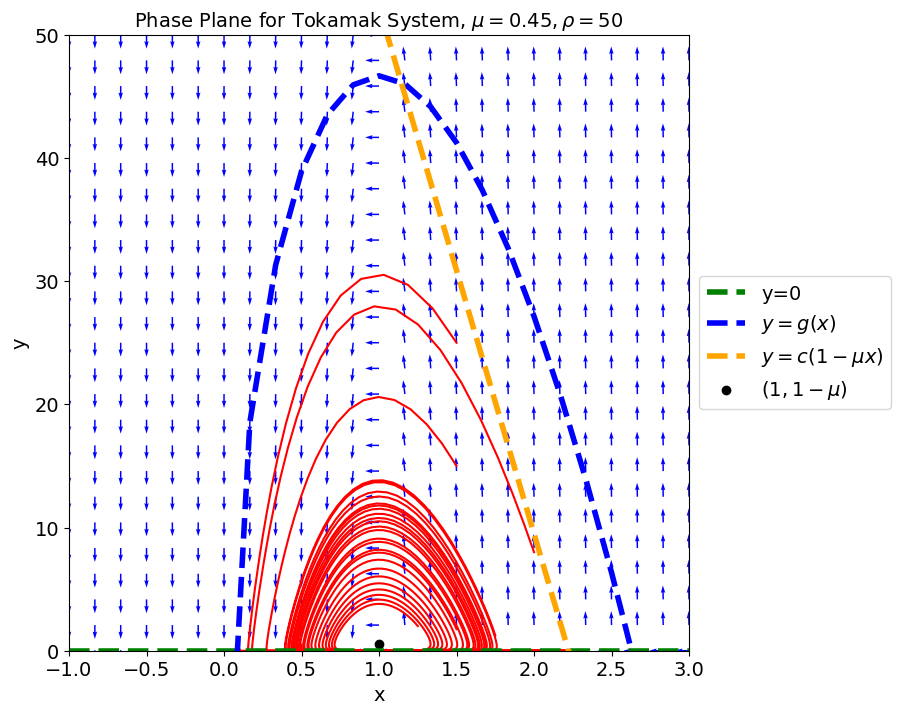

In [40]:
##Note: The code for the phase plane and state-space trajectory is taken from:
#https://aleksandarhaber.com/phase-portraits-of-state-space-models-and-differential-equations-in-python/#google_vignette$0

import matplotlib.pyplot as plt
from scipy.integrate import odeint
import numpy as np

# first create create a function that evaluates the right-hand-side of the
# state-space equations for a given state vector

# x is the current state vector
# t is current simulation time

def dynamicsStateSpace(x,t):
    # Make sure x0, x1 nonegative to avoid fractional power errors
    x0_val = max(0.0, x[0])
    x1_val = max(0.0, x[1])
    dxdt=[(1-(0.45)*x0_val)*x0_val**(3/2)-(x0_val**(1/2) * x1_val), 50 * (x0_val - 1) * x1_val]
    return dxdt

# next, define a grid of points at which we will show arrows
x0=np.linspace(-1,3,25)
x1=np.linspace(0,50,25)

# create a grid
X0,X1=np.meshgrid(x0,x1)
# projections of the trajectory tangent vector
dX0=np.zeros(X0.shape)
dX1=np.zeros(X1.shape)

shape1,shape2=X1.shape

for indexShape1 in range(shape1):
    for indexShape2 in range(shape2):
        dxdtAtX=dynamicsStateSpace([X0[indexShape1,indexShape2],X1[indexShape1,indexShape2]],0)
        dX0[indexShape1,indexShape2]=dxdtAtX[0]
        dX1[indexShape1,indexShape2]=dxdtAtX[1]

# Calculate the magnitude of the vectors (so vectors in phase plot are all the same size)
M = (dX0**2 + dX1**2)**0.5
M[M == 0] = 1.0  # Avoid division by zero

# plot the dynamics on the same graph
initialState_1=np.array([1.75,1.25]) # Changed negative initial values to avoid nan complex roots
simulationTime_1=np.linspace(0,50,10000)
# generate the state-space trajectory
solutionState_1=odeint(dynamicsStateSpace,initialState_1,simulationTime_1)

# plot the dynamics on the same graph
initialState_2=np.array([0.5,0.5])
simulationTime_2=np.linspace(0,50,10000)
# generate the state-space trajectory
solutionState_2=odeint(dynamicsStateSpace,initialState_2,simulationTime_2)

# plot the dynamics on the same graph
initialState_3=np.array([0.1,0.1])
simulationTime_3=np.linspace(0,50,10000)
# generate the state-space trajectory
solutionState_3=odeint(dynamicsStateSpace,initialState_3,simulationTime_3)

# plot the dynamics on the same graph
initialState_4=np.array([1.5,1.75])
simulationTime_4=np.linspace(0,50,10000)
# generate the state-space trajectory
solutionState_4=odeint(dynamicsStateSpace,initialState_4,simulationTime_4)

# plot the dynamics on the same graph
initialState_5=np.array([2,8])
simulationTime_5=np.linspace(0,50,10000)
# generate the state-space trajectory
solutionState_5=odeint(dynamicsStateSpace,initialState_5,simulationTime_5)

# plot the dynamics on the same graph
initialState_6=np.array([1.25,2])
simulationTime_6=np.linspace(0,50,10000)
# generate the state-space trajectory
solutionState_6=odeint(dynamicsStateSpace,initialState_6,simulationTime_6)

# plot the dynamics on the same graph
initialState_7=np.array([1.5,25])
simulationTime_7=np.linspace(0,50,10000)
# generate the state-space trajectory
solutionState_7=odeint(dynamicsStateSpace,initialState_7,simulationTime_7)

# plot the dynamics on the same graph
initialState_8=np.array([1.5,15])
simulationTime_8=np.linspace(0,50,10000)
# generate the state-space trajectory
solutionState_8=odeint(dynamicsStateSpace,initialState_8,simulationTime_8)


#adjust the figure size
plt.figure(figsize=(8, 8))
# plot the phase portrait
plt.quiver(X0,X1,dX0/M,dX1/M,color='b')

# add the state trajectory plot
plt.plot(solutionState_1[:,0], solutionState_1[:,1], 'r-')
plt.plot(solutionState_2[:,0], solutionState_2[:,1], 'r-')
plt.plot(solutionState_3[:,0], solutionState_3[:,1], 'r-')
plt.plot(solutionState_4[:,0], solutionState_4[:,1], 'r-')
plt.plot(solutionState_5[:,0], solutionState_5[:,1], 'r-')
plt.plot(solutionState_6[:,0], solutionState_6[:,1], 'r-')
plt.plot(solutionState_7[:,0], solutionState_7[:,1], 'r-')
plt.plot(solutionState_8[:,0], solutionState_8[:,1], 'r-')


plt.axhline(y=0, color='green', linestyle='--', label='y=0', linewidth=4)
plt.plot(x0, -2/3 * (50) * (x0-3) * np.sqrt(x0) - 20, linestyle='--', color = 'b', label=r'$y=g(x)$', linewidth=4)
plt.plot(x0, 95*(1-(0.45)*x0), color='orange', linestyle='--', label=r'$y=c(1-\mu x)$', linewidth=4)
plt.scatter(1, 1-0.45, color='black', label=r'$(1, 1-\mu)$')

plt.xlim(-1,3)
plt.ylim(0,50)

# insert the title
plt.title(r'Phase Plane for Tokamak System, $\mu=0.45, \rho=50$ ', fontsize=14)
# set the axis labels
plt.xlabel('x',fontsize=14)
plt.ylabel('y',fontsize=14)
# adjust the font size of x and y axes
plt.tick_params(axis='both', which='major', labelsize=14)
# insert legend
plt.legend(fontsize=14, loc='center left', bbox_to_anchor=(1, 0.5))
plt.show()

##Part e

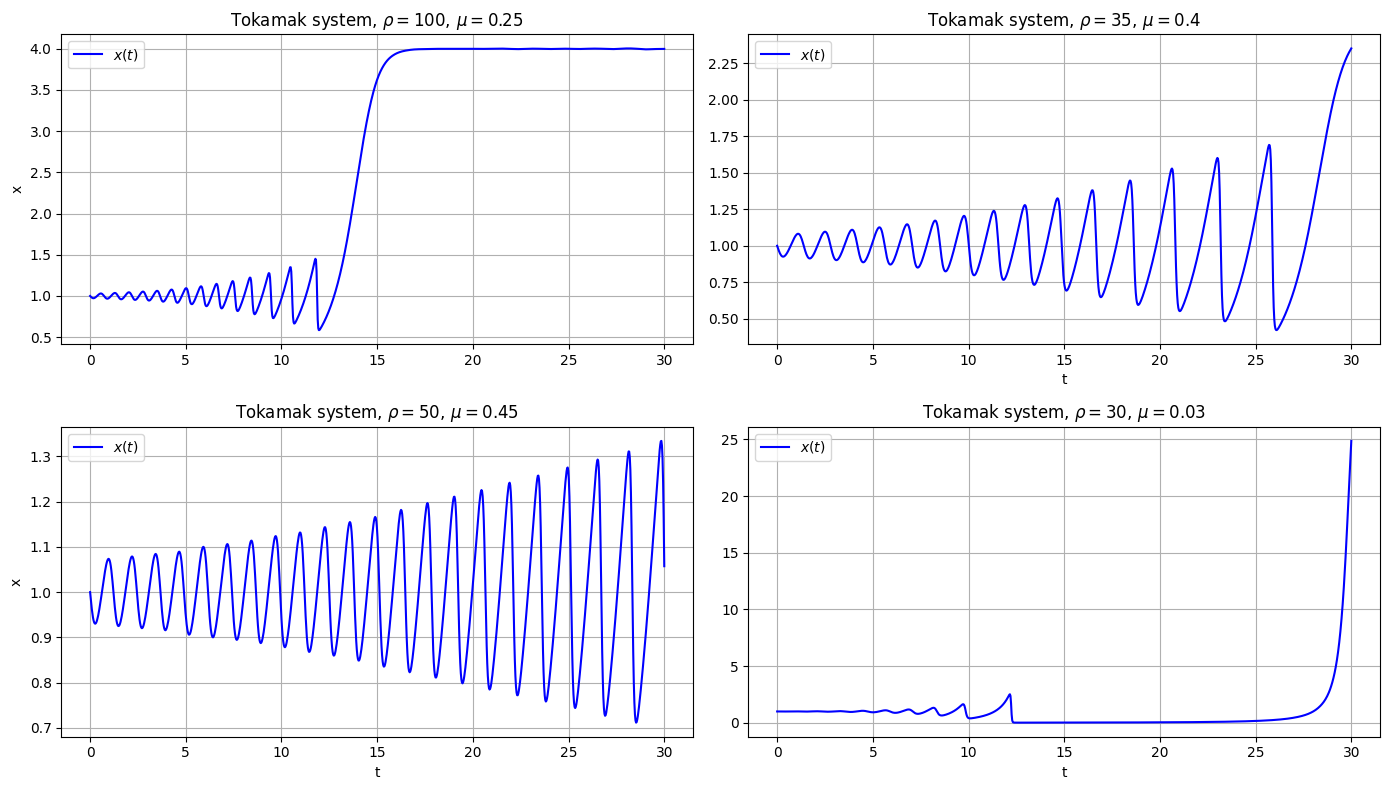

In [39]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

#Help for solving the IVP came from https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_ivp.html

# Define the reduced tokamak
def tokamak_system(t, z, mu, rho):
    x, y = z
    if x < 0:
        x = 0
    if y < 0:
        y = 0
    return [(1-mu*x) * x**(3/2) - x**(1/2) * y, rho * (x-1) * y]

#Define time interval using np.linspace
t = np.linspace(0, 30, 1000)

#Create two separate subplots
fig, axs = plt.subplots(2, 2, figsize=(14, 8))

# Initial conditions are # [x(0), y(0)]= [1, 1]
# Large value for rho, 0<mu<0.5
sol_1 = solve_ivp(tokamak_system, [0, 30], [1,1], args=(0.25, 100), t_eval=t)
x_1_func, y_1_func = sol_1.y

# Plot x(t)
axs[0, 0].plot(t, x_1_func, color='b', label=f'$x(t)$')
axs[0, 0].set_ylabel('x')
axs[0, 0].set_title(r'Tokamak system, $\rho=100,\, \mu=0.25$')
axs[0, 0].legend()
axs[0, 0].grid(True)

sol_2 = solve_ivp(tokamak_system, [0, 30], [1,1], args=(0.45, 50), t_eval=t)
x_2_func, y_2_func = sol_2.y

# Plot x(t)
axs[1, 0].plot(t, x_2_func, color='b', label=f'$x(t)$')
axs[1, 0].set_ylabel('x')
axs[1, 0].set_xlabel('t')
axs[1, 0].set_title(r'Tokamak system, $\rho=50,\, \mu=0.45$')
axs[1, 0].legend()
axs[1, 0].grid(True)

sol_3 = solve_ivp(tokamak_system, [0, 30], [1,1], args=(0.03, 30), t_eval=t)
x_3_func, y_3_func = sol_3.y

# Plot x(t)
axs[1, 1].plot(t, x_3_func, color='b', label=f'$x(t)$')
axs[1, 1].set_xlabel('t')
axs[1, 1].set_title(r'Tokamak system, $\rho=30,\, \mu=0.03$')
axs[1, 1].legend()
axs[1, 1].grid(True)

sol_4 = solve_ivp(tokamak_system, [0, 30], [1,1], args=(0.4, 35), t_eval=t)
x_4_func, y_4_func = sol_4.y

# Plot x(t)
axs[0, 1].plot(t, x_4_func, color='b', label=f'$x(t)$')
axs[0, 1].set_xlabel('t')
axs[0, 1].set_title(r'Tokamak system, $\rho=35,\, \mu=0.4$')
axs[0, 1].legend()
axs[0, 1].grid(True)


plt.tight_layout()
plt.show()